# EN3160 Assignment 1 - Intensity Transformations and Neighborhood Filtering
**D. P. Heshan Ranasinghe | Index: 230521E | [GitHub](https://github.com/DPHeshanRanasinghe)**

In [1]:
from pathlib import Path
import cv2 # type: ignore
import matplotlib.pyplot as plt # type: ignore
import numpy as np # type: ignore

IMAGE_DIR = Path("images")
plt.rcParams.update({"font.size": 8, "figure.dpi": 130})

## 1. Piecewise intensity transformation
The vertical lines in Fig. 1a are jumps in the transformation, so the input values 50 and 150 appear twice. I used linear interpolation only between points with different input values.

In [2]:
def intensity_transform(im, breakpoints):
    breakpoints = np.asarray(breakpoints, dtype=float)
    transformed = np.zeros(im.shape, dtype=float)

    for (x1, y1), (x2, y2) in zip(breakpoints[:-1], breakpoints[1:]):
        if x1 == x2:                 # vertical jump
            continue
        mask = (im >= x1) & (im < x2)
        transformed[mask] = y1 + (im[mask] - x1) * (y2 - y1) / (x2 - x1)

    transformed[im == breakpoints[-1, 0]] = breakpoints[-1, 1]
    return np.clip(np.rint(transformed), 0, 255).astype(np.uint8)

# Points read directly from Fig. 1a (repeated x-values draw the jumps)
figure_breakpoints = np.array([
    [0, 0], [50, 50], [50, 100], [150, 255], [150, 150], [255, 255]
])

# Continuous points chosen after observing the banding in Fig. 1a
chosen_breakpoints = np.array([
    [0, 0], [50, 75], [150, 200], [255, 255]
])

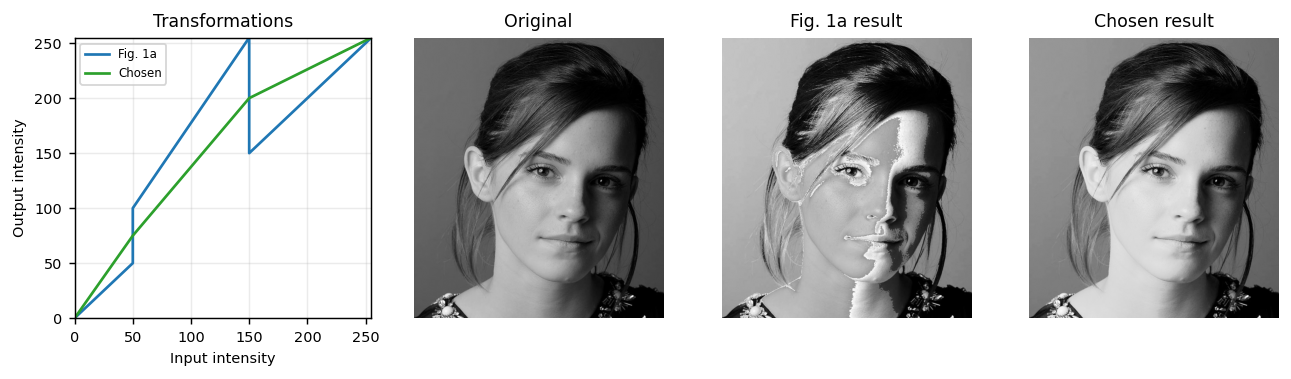

Chosen result - mean: 92.3 -> 121.7, standard deviation: 56.1 -> 65.9


In [3]:
image = cv2.imread(str(IMAGE_DIR / "q01_portrait_intensity_transform.jpeg"), cv2.IMREAD_GRAYSCALE)
if image is None:
    raise FileNotFoundError("Question 1 image was not found")

figure_result = intensity_transform(image, figure_breakpoints)
chosen_result = intensity_transform(image, chosen_breakpoints)

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), constrained_layout=True)
axes[0].plot(figure_breakpoints[:, 0], figure_breakpoints[:, 1], color="tab:blue", label="Fig. 1a")
axes[0].plot(chosen_breakpoints[:, 0], chosen_breakpoints[:, 1], color="tab:green", label="Chosen")
axes[0].set(xlabel="Input intensity", ylabel="Output intensity", xlim=(0, 255), ylim=(0, 255), title="Transformations")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=6.5)

for ax, result, title in zip(axes[1:], [image, figure_result, chosen_result], ["Original", "Fig. 1a result", "Chosen result"]):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()
print(f"Chosen result - mean: {image.mean():.1f} -> {chosen_result.mean():.1f}, standard deviation: {image.std():.1f} -> {chosen_result.std():.1f}")

**Interpretation.** The Fig. 1a transformation brightens intensities from 50 to 149 strongly, but its sudden jumps produce bright bands on the face. I therefore removed the jumps and tested the continuous points $(0,0)$, $(50,75)$, $(150,200)$ and $(255,255)$. This curve stays above the identity line, so it brightens the darker and middle intensities smoothly. The mean increased from **92.3 to 121.7** and the standard deviation from **56.1 to 65.9**, giving a clearer image without the harsh bands.

## 2. Accentuating white matter and gray matter
White matter and gray matter are tissue types, not simply white and gray pixels. In this proton-density image, white matter is mainly in the lower tissue range (about 150-180), while gray matter is slightly brighter (about 180-210). Separate piecewise transformations were used to brighten each range.

In [4]:
brain = cv2.imread(str(IMAGE_DIR / "q02_brain_proton_density.jpeg"), cv2.IMREAD_GRAYSCALE)

white_matter_breakpoints = np.array([
    [0, 0], [150, 110], [150, 225], [180, 255], [180, 125], [255, 210]
])
gray_matter_breakpoints = np.array([
    [0, 0], [180, 120], [180, 225], [210, 255], [210, 140], [255, 210]
])

white_matter_result = intensity_transform(brain, white_matter_breakpoints)
gray_matter_result = intensity_transform(brain, gray_matter_breakpoints)

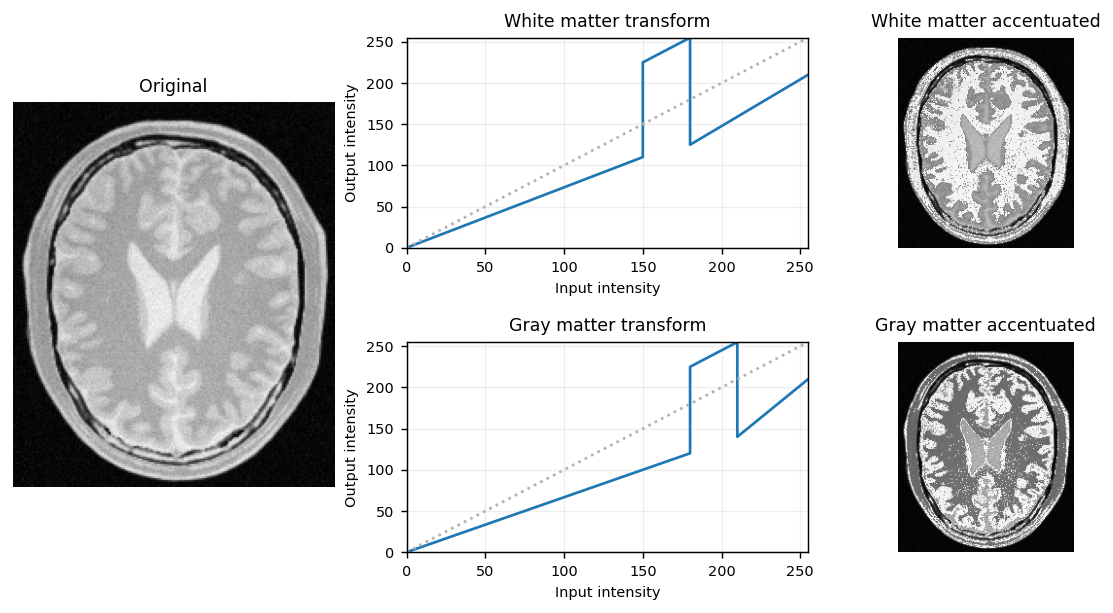

In [5]:
fig = plt.figure(figsize=(8.8, 4.6), constrained_layout=True)
grid = fig.add_gridspec(2, 3, width_ratios=[0.8, 1, 0.8])
original_ax = fig.add_subplot(grid[:, 0])
white_plot_ax, white_image_ax = fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[0, 2])
gray_plot_ax, gray_image_ax = fig.add_subplot(grid[1, 1]), fig.add_subplot(grid[1, 2])

original_ax.imshow(brain, cmap="gray", vmin=0, vmax=255)
original_ax.set_title("Original")
original_ax.axis("off")

for ax, points, title in [(white_plot_ax, white_matter_breakpoints, "White matter transform"), (gray_plot_ax, gray_matter_breakpoints, "Gray matter transform")]:
    ax.plot(points[:, 0], points[:, 1])
    ax.plot([0, 255], [0, 255], ":", color="0.7")
    ax.set(xlabel="Input intensity", ylabel="Output intensity", xlim=(0, 255), ylim=(0, 255), title=title)
    ax.grid(alpha=0.2)

for ax, result, title in [(white_image_ax, white_matter_result, "White matter accentuated"), (gray_image_ax, gray_matter_result, "Gray matter accentuated")]:
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Interpretation.** The first transformation raises intensities from 150 to 180, making the inner white-matter regions more visible. The second raises the 180 to 210 range, so the gray-matter structures around the outer part of the brain stand out. Some fluid and skull pixels are also enhanced because intensity alone cannot separate tissues that have similar gray levels.

## 3. Gamma correction in the L*a*b* color space
Gamma correction was applied only to the lightness ($L$) plane using $L_{new}=255(L/255)^{\gamma}$. Values 0.5, 0.65 and 0.8 were compared, and **$\gamma=0.65$** was selected.

In [6]:
image_bgr = cv2.imread(str(IMAGE_DIR / "q03_white_dress_gamma_correction.jpeg"))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
L, a, b = cv2.split(lab)

gamma = 0.65
L_corrected = 255 * (L / 255.0) ** gamma
L_corrected = np.clip(L_corrected, 0, 255).astype(np.uint8)
corrected_lab = cv2.merge([L_corrected, a, b])
corrected_rgb = cv2.cvtColor(corrected_lab, cv2.COLOR_LAB2RGB)

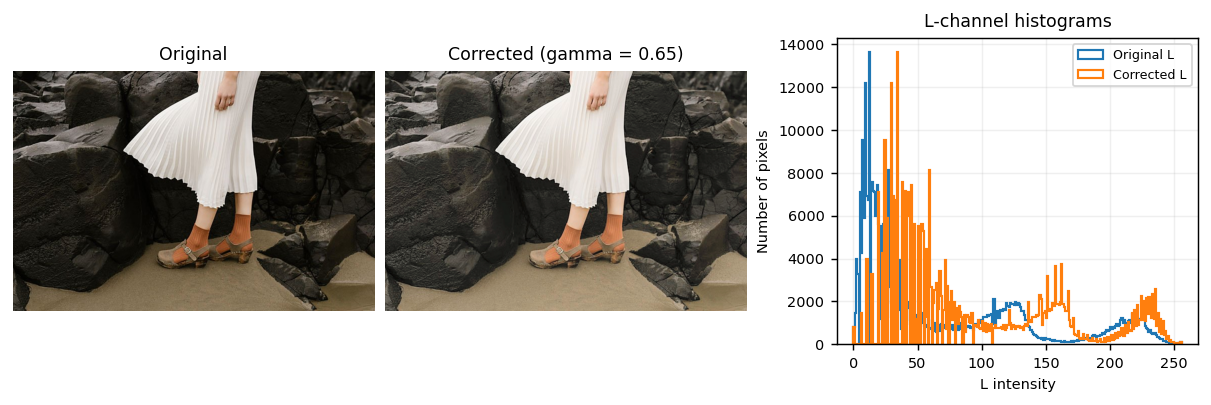

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.0), constrained_layout=True)
axes[0].imshow(image_rgb)
axes[0].set_title("Original")
axes[1].imshow(corrected_rgb)
axes[1].set_title(f"Corrected (gamma = {gamma})")
for ax in axes[:2]:
    ax.axis("off")
 
axes[2].hist(L.ravel(), bins=256, range=(0, 256),
             histtype="step", color="tab:blue", linewidth=1.2,
             label="Original L")
axes[2].hist(L_corrected.ravel(), bins=256, range=(0, 256),
             histtype="step", color="tab:orange", linewidth=1.2,
             label="Corrected L")
axes[2].set_xlabel("L intensity")
axes[2].set_ylabel("Number of pixels")
axes[2].set_title("L-channel histograms")
axes[2].legend(fontsize=7)
axes[2].grid(alpha=0.2)
plt.show()
 

**Interpretation.** Since $\gamma<1$, lower $L$ values are increased more than high values. With $\gamma=0.65$, detail in the dark rocks becomes clearer while the white dress remains bright. The $L$ histogram moves to the right and its mean increases from **71.3 to 98.6**. A value of 0.5 looked washed out, while 0.8 made only a small change. The $a$ and $b$ planes were kept unchanged, so the color information was preserved.

## 4. Vibrance enhancement in HSV
The given transformation was applied only to the saturation plane with $\sigma=70$. Values $a=0.3$, $0.5$ and $0.7$ were compared, and **$a=0.5$** was selected.

In [8]:
q4_bgr = cv2.imread(str(IMAGE_DIR / "q04_spiderman_vibrance.jpeg"))
q4_rgb = cv2.cvtColor(q4_bgr, cv2.COLOR_BGR2RGB)
q4_hsv = cv2.cvtColor(q4_bgr, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(q4_hsv)

a_value, sigma = 0.5, 70
x = np.arange(256, dtype=float)
transform = np.minimum(x + a_value * 128 * np.exp(-((x - 128) ** 2) / (2 * sigma ** 2)), 255)
S_enhanced = np.rint(transform).astype(np.uint8)[S]
enhanced_hsv = cv2.merge([H, S_enhanced, V])
enhanced_rgb = cv2.cvtColor(enhanced_hsv, cv2.COLOR_HSV2RGB)

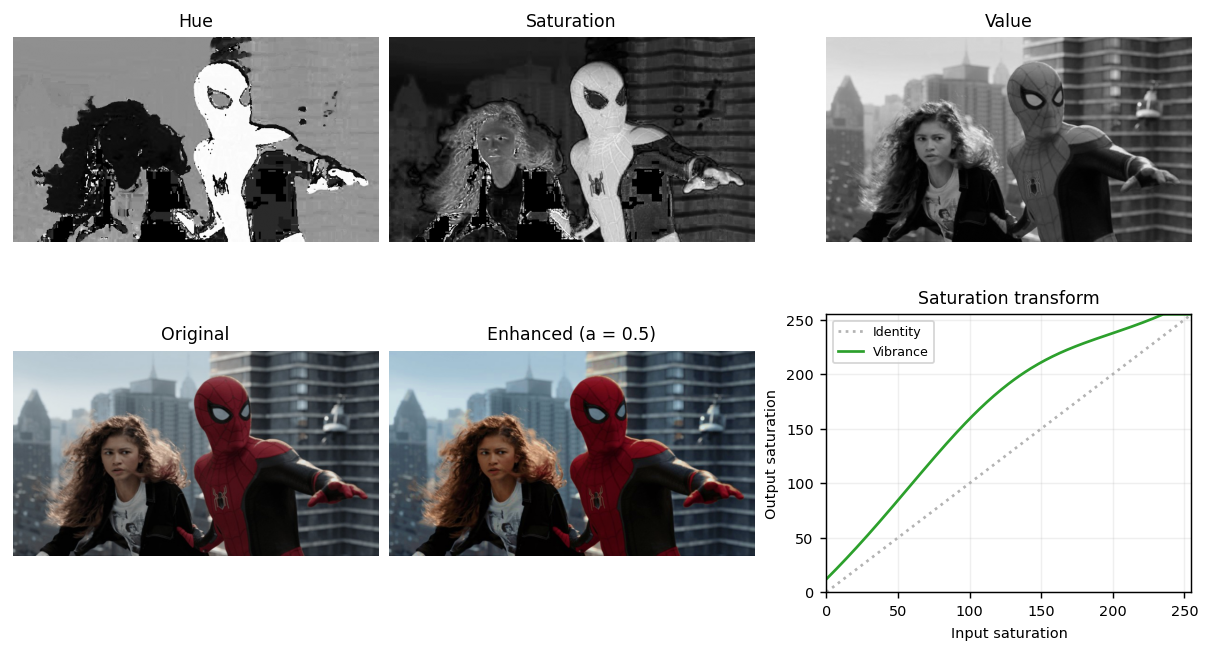

Mean saturation: 62.1 -> 94.3


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(9.2, 5.0), constrained_layout=True)
for ax, plane, title, vmax in zip(axes[0], [H, S, V], ["Hue", "Saturation", "Value"], [179, 255, 255]):
    ax.imshow(plane, cmap="gray", vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")

axes[1, 0].imshow(q4_rgb)
axes[1, 0].set_title("Original")
axes[1, 1].imshow(enhanced_rgb)
axes[1, 1].set_title(f"Enhanced (a = {a_value})")
for ax in axes[1, :2]:
    ax.axis("off")

axes[1, 2].plot(x, x, ":", color="0.7", label="Identity")
axes[1, 2].plot(x, transform, color="tab:green", label="Vibrance")
axes[1, 2].set(xlabel="Input saturation", ylabel="Output saturation", xlim=(0, 255), ylim=(0, 255), title="Saturation transform")
axes[1, 2].legend(fontsize=7)
axes[1, 2].grid(alpha=0.2)
plt.show()
print(f"Mean saturation: {S.mean():.1f} -> {S_enhanced.mean():.1f}")

**Interpretation.** With $a=0.5$, the mean saturation increased from **62.1 to 94.3**, making Spider-Man's suit and the scene more vivid without changing hue or brightness. The effect at $a=0.3$ was small, while $a=0.7$ made some colors look too strong. Therefore, 0.5 gave the best visual balance.

## 5. Histogram equalization
A custom histogram-equalization function was applied to improve the global contrast of Fig. 5.

In [10]:
def histogram_equalization(im):
    histogram = np.bincount(im.ravel(), minlength=256)
    cdf = histogram.cumsum()
    cdf_min = cdf[cdf > 0][0]
    if cdf_min == im.size:
        return im.copy()
    lut = np.round((cdf - cdf_min) * 255 / (im.size - cdf_min))
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[im]

shells = cv2.imread(str(IMAGE_DIR / "q05_shells_histogram_equalization.tif"), cv2.IMREAD_GRAYSCALE)
equalized_shells = histogram_equalization(shells)

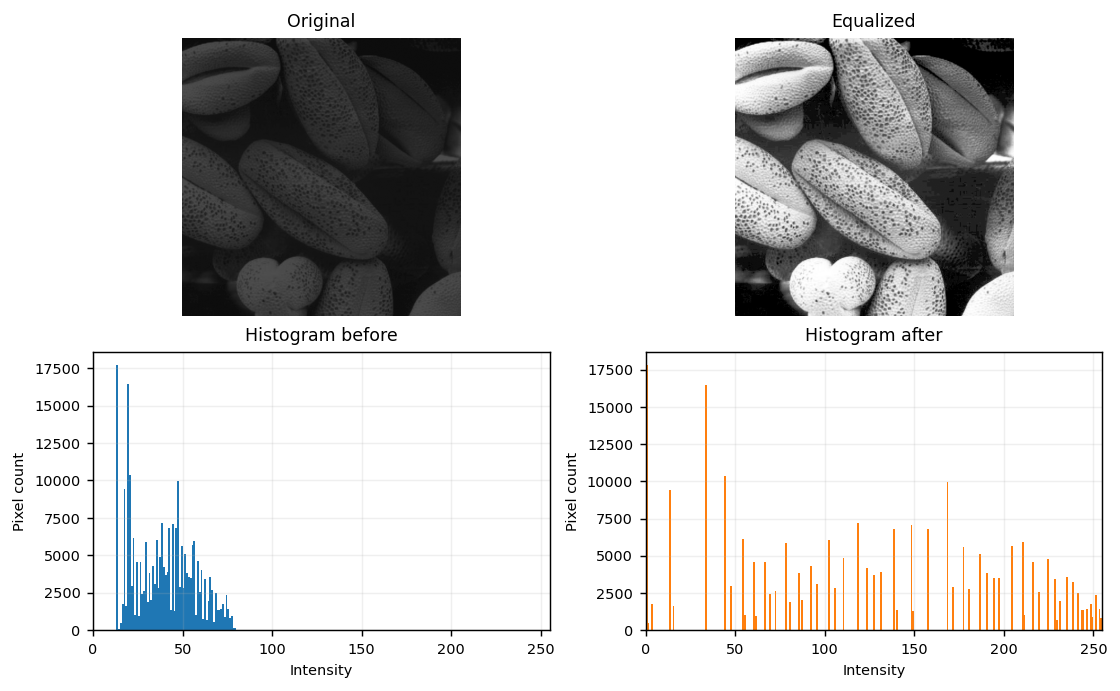

Intensity range: 13-83 -> 0-255


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.2), constrained_layout=True)
axes[0, 0].imshow(shells, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 1].imshow(equalized_shells, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Equalized")
for ax in axes[0]:
    ax.axis("off")

axes[1, 0].hist(shells.ravel(), bins=256, range=(0, 256), color="tab:blue")
axes[1, 0].set_title("Histogram before")
axes[1, 1].hist(equalized_shells.ravel(), bins=256, range=(0, 256), color="tab:orange")
axes[1, 1].set_title("Histogram after")
for ax in axes[1]:
    ax.set(xlabel="Intensity", ylabel="Pixel count", xlim=(0, 255))
    ax.grid(alpha=0.2)
plt.show()
print(f"Intensity range: {shells.min()}-{shells.max()} -> {equalized_shells.min()}-{equalized_shells.max()}")

**Interpretation.** The original histogram is concentrated in the darker intensity range, so some shell details have low contrast. Equalization uses the normalized cumulative histogram (CDF) to spread the occupied levels across 0-255. The result reveals more shell texture and separates the shells from the background more clearly. The final histogram is not perfectly uniform because the image contains discrete gray levels with repeated pixel counts.

## 6. Histogram equalization of the foreground
The saturation plane separates the coloured subject from the nearly grey background. Histogram equalization is then applied only to the foreground value intensities.

In [12]:
q6_bgr = cv2.imread(str(IMAGE_DIR / "q06_portrait_foreground_equalization.jpeg"))
q6_rgb = cv2.cvtColor(q6_bgr, cv2.COLOR_BGR2RGB)
H6, S6, V6 = cv2.split(cv2.cvtColor(q6_bgr, cv2.COLOR_BGR2HSV))

# Threshold saturation and retain the filled main foreground region.
_, rough_mask = cv2.threshold(S6, 20, 255, cv2.THRESH_BINARY)
rough_mask = cv2.morphologyEx(rough_mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
contours, _ = cv2.findContours(rough_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
mask6 = np.zeros_like(S6)
cv2.drawContours(mask6, [max(contours, key=cv2.contourArea)], -1, 255, cv2.FILLED)

foreground_V = cv2.bitwise_and(V6, V6, mask=mask6)
hist6 = np.bincount(foreground_V[mask6 > 0], minlength=256)
cdf6 = np.cumsum(hist6)
cdf_min6 = cdf6[cdf6 > 0][0]
lut6 = np.round((cdf6 - cdf_min6) * 255 / (cdf6[-1] - cdf_min6))
lut6 = np.clip(lut6, 0, 255).astype(np.uint8)

equalized_hsv = cv2.merge([H6, S6, lut6[V6]])
equalized_rgb = cv2.cvtColor(equalized_hsv, cv2.COLOR_HSV2RGB)
equalized_foreground = cv2.bitwise_and(equalized_rgb, equalized_rgb, mask=mask6)
background = cv2.bitwise_and(q6_rgb, q6_rgb, mask=cv2.bitwise_not(mask6))
q6_result = cv2.add(equalized_foreground, background)

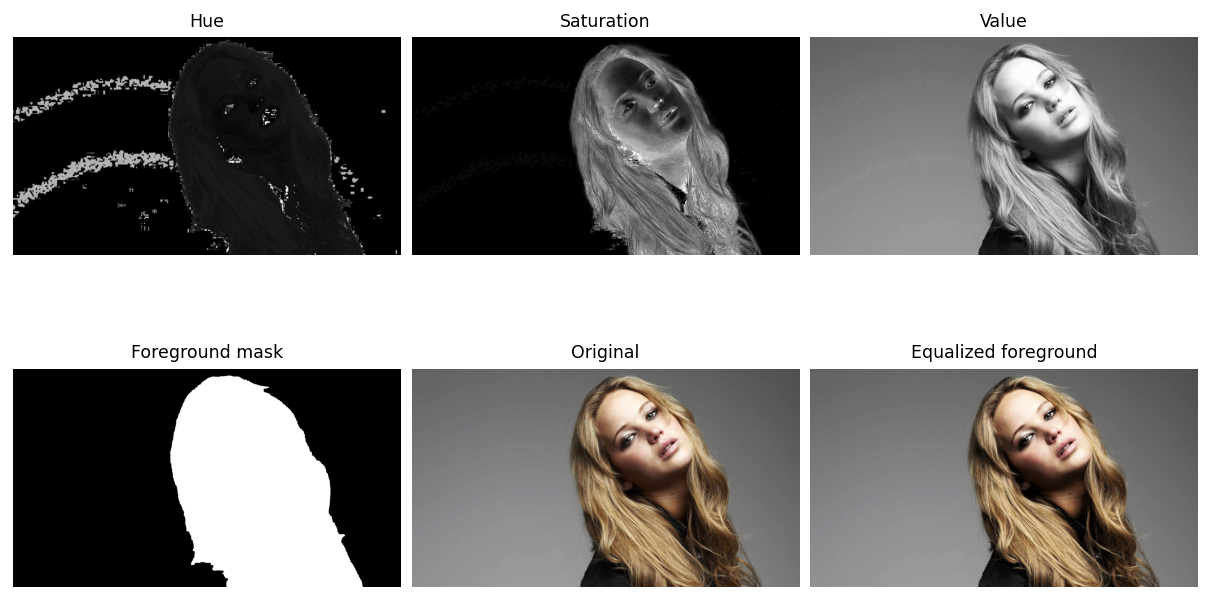

Foreground value standard deviation: 65.0 -> 73.6


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(9.2, 5.1), constrained_layout=True)
for ax, plane, title in zip(axes[0], [H6, S6, V6], ["Hue", "Saturation", "Value"]):
    ax.imshow(plane, cmap="gray")
    ax.set_title(title)

axes[1, 0].imshow(mask6, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Foreground mask")
axes[1, 1].imshow(q6_rgb)
axes[1, 1].set_title("Original")
axes[1, 2].imshow(q6_result)
axes[1, 2].set_title("Equalized foreground")
for ax in axes.ravel():
    ax.axis("off")
plt.show()
print(f"Foreground value standard deviation: {V6[mask6 > 0].std():.1f} -> {lut6[V6][mask6 > 0].std():.1f}")

**Interpretation.** The low saturation of the grey background makes the saturation plane suitable for extracting the subject. The normalized CDF spreads only the foreground value intensities across the available range, increasing detail and contrast in the face, hair, and clothing. Hue and saturation are retained, while the background pixels are copied from the original image and therefore remain unchanged.

## 7. Sobel filtering
The horizontal and vertical Sobel responses are combined as $G=\sqrt{G_x^2+G_y^2}$. The result is computed using `filter2D`, a manual convolution, and separable 1-D filters.

In [14]:
q7_gray = cv2.imread(str(IMAGE_DIR / "q07_einstein_sobel.jpeg"), cv2.IMREAD_GRAYSCALE)
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = sobel_x.T

# (a) OpenCV filter2D
gx_filter2d = cv2.filter2D(q7_gray, cv2.CV_64F, sobel_x, borderType=cv2.BORDER_REFLECT_101)
gy_filter2d = cv2.filter2D(q7_gray, cv2.CV_64F, sobel_y, borderType=cv2.BORDER_REFLECT_101)

# (b) Manual spatial filtering
def manual_filter2d(im, kernel):
    padded = np.pad(im.astype(float), 1, mode="reflect")
    result = np.zeros(im.shape, dtype=float)
    for row in range(im.shape[0]):
        for col in range(im.shape[1]):
            result[row, col] = np.sum(padded[row:row + 3, col:col + 3] * kernel)
    return result

gx_manual = manual_filter2d(q7_gray, sobel_x)
gy_manual = manual_filter2d(q7_gray, sobel_y)

# (c) Separable Sobel filters
smooth_col = np.array([[1], [2], [1]], dtype=float)
derivative_row = np.array([[-1, 0, 1]], dtype=float)
gx_separable = cv2.filter2D(cv2.filter2D(q7_gray, cv2.CV_64F, derivative_row), cv2.CV_64F, smooth_col)
gy_separable = cv2.filter2D(cv2.filter2D(q7_gray, cv2.CV_64F, smooth_col.T), cv2.CV_64F, derivative_row.T)

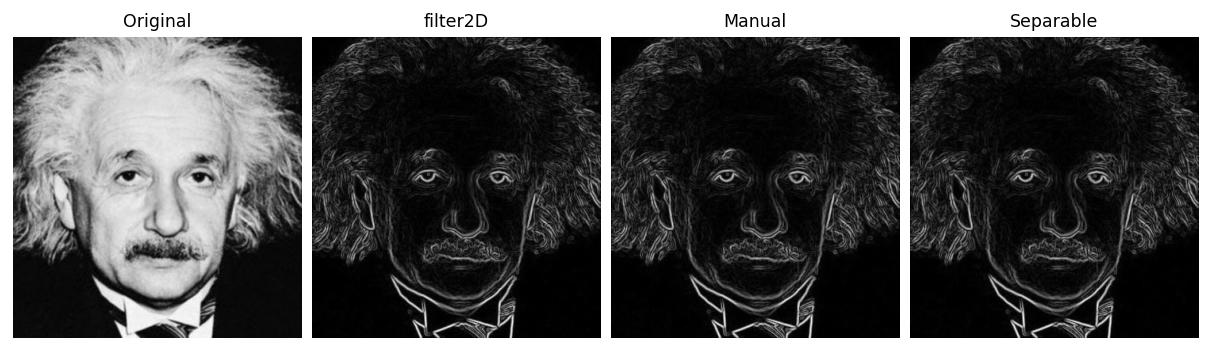

Maximum difference from filter2D: manual = 0.0, separable = 0.0


In [15]:
def show_magnitude(gx, gy):
    magnitude = np.hypot(gx, gy)
    return cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

results7 = [q7_gray, show_magnitude(gx_filter2d, gy_filter2d),
            show_magnitude(gx_manual, gy_manual), show_magnitude(gx_separable, gy_separable)]
titles7 = ["Original", "filter2D", "Manual", "Separable"]
fig, axes = plt.subplots(1, 4, figsize=(9.2, 3.0), constrained_layout=True)
for ax, image, title in zip(axes, results7, titles7):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()
manual_error = max(np.abs(gx_filter2d - gx_manual).max(), np.abs(gy_filter2d - gy_manual).max())
separable_error = max(np.abs(gx_filter2d - gx_separable).max(), np.abs(gy_filter2d - gy_separable).max())
print(f"Maximum difference from filter2D: manual = {manual_error:.1f}, separable = {separable_error:.1f}")

**Comparison.** All three methods produce the same edge map and emphasize Einstein's facial features, hair, and clothing boundaries. The zero numerical differences confirm that the manual and separable implementations match `filter2D`. The manual nested loops are the slowest, while separability reduces each $3\times3$ Sobel operation to two 1-D operations and is therefore more efficient.

## 8. Image zooming
A single function implements nearest-neighbour and bilinear interpolation for any scale $s\in(0,10]$. The two small images are enlarged by a factor of 4 and compared with their originals.

In [16]:
def zoom_image(im, scale, method="nearest"):
    if not 0 < scale <= 10:
        raise ValueError("scale must be in (0, 10]")
    if method not in ("nearest", "bilinear"):
        raise ValueError("method must be 'nearest' or 'bilinear'")

    height, width = im.shape[:2]
    new_height, new_width = round(height * scale), round(width * scale)
    y = np.arange(new_height) / scale
    x = np.arange(new_width) / scale

    if method == "nearest":
        yi = np.clip(np.rint(y).astype(int), 0, height - 1)
        xi = np.clip(np.rint(x).astype(int), 0, width - 1)
        return im[yi[:, None], xi[None, :]]

    y0 = np.floor(y).astype(int)
    x0 = np.floor(x).astype(int)
    y1 = np.clip(y0 + 1, 0, height - 1)
    x1 = np.clip(x0 + 1, 0, width - 1)
    wy, wx = y - y0, x - x0
    if im.ndim == 3:
        wy, wx = wy[:, None, None], wx[None, :, None]
    else:
        wy, wx = wy[:, None], wx[None, :]

    a = im[y0[:, None], x0[None, :]].astype(np.float32)
    b = im[y0[:, None], x1[None, :]].astype(np.float32)
    c = im[y1[:, None], x0[None, :]].astype(np.float32)
    d = im[y1[:, None], x1[None, :]].astype(np.float32)
    result = (1 - wy) * ((1 - wx) * a + wx * b) + wy * ((1 - wx) * c + wx * d)
    return np.clip(np.rint(result), 0, 255).astype(np.uint8)

def normalized_ssd(reference, test):
    difference = reference.astype(float) - test.astype(float)
    return np.mean(difference ** 2) / (255 ** 2)

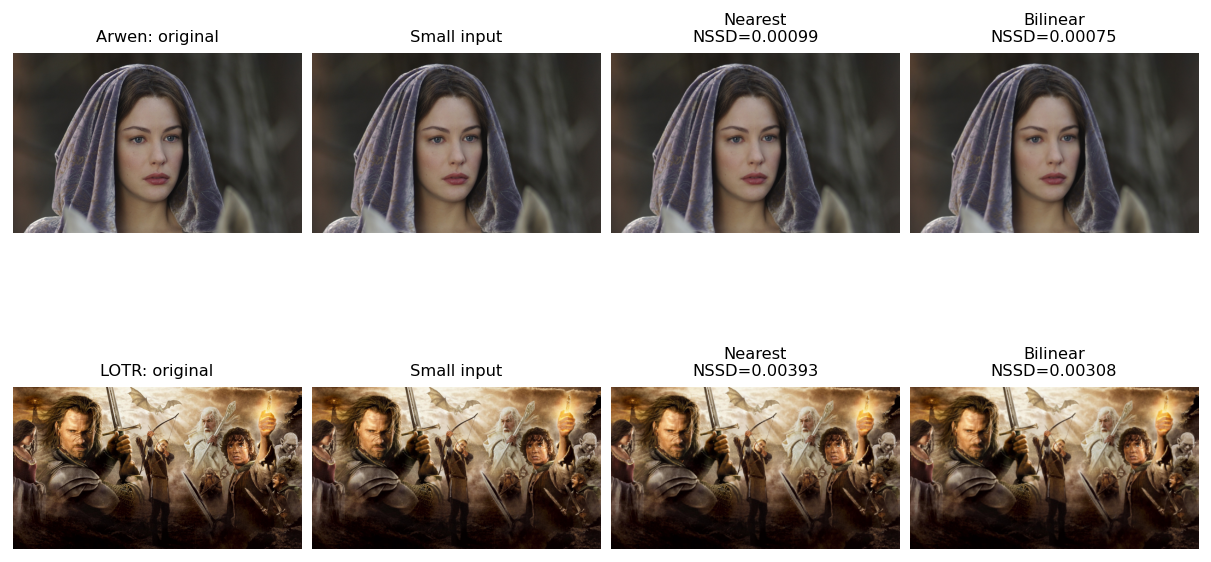

Image    Nearest NSSD    Bilinear NSSD
Arwen    0.000994        0.000754
LOTR     0.003926        0.003078


In [17]:
q8_pairs = [
    ("Arwen", "q08_arwen_portrait_480x300.png", "q08_arwen_portrait_1920x1200.png"),
    ("LOTR", "q08_lord_of_the_rings_480x270.png", "q08_lord_of_the_rings_1920x1080.png")
]
q8_results = []
for name, small_file, original_file in q8_pairs:
    small = cv2.cvtColor(cv2.imread(str(IMAGE_DIR / small_file)), cv2.COLOR_BGR2RGB)
    original = cv2.cvtColor(cv2.imread(str(IMAGE_DIR / original_file)), cv2.COLOR_BGR2RGB)
    nearest = zoom_image(small, 4, "nearest")
    bilinear = zoom_image(small, 4, "bilinear")
    q8_results.append((name, original, small, nearest, bilinear,
                       normalized_ssd(original, nearest), normalized_ssd(original, bilinear)))

fig, axes = plt.subplots(2, 4, figsize=(9.2, 5.0), constrained_layout=True)
for row, (name, original, small, nearest, bilinear, nn_score, bi_score) in enumerate(q8_results):
    for ax, image, title in zip(axes[row], [original, small, nearest, bilinear],
                                [f"{name}: original", "Small input",
                                 f"Nearest\nNSSD={nn_score:.5f}", f"Bilinear\nNSSD={bi_score:.5f}"]):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
plt.show()
print("Image    Nearest NSSD    Bilinear NSSD")
for name, *_, nn_score, bi_score in q8_results:
    print(f"{name:5s}    {nn_score:.6f}        {bi_score:.6f}")

**Comparison.** Nearest-neighbour interpolation copies the closest pixel, producing visible block boundaries after 4x enlargement. Bilinear interpolation uses a weighted average of four neighbouring pixels, giving smoother edges and a lower normalized SSD for both test images. Therefore, bilinear interpolation reproduces the large reference images more accurately, although it requires more computation.